# 01. Análise Exploratória de Dados (EDA) e Processamento de Imagens
### Classificação de Patologias em Folhas de Macieira (*Plant Pathology 2020 - FGVC7*)

Este notebook implementa a **Etapa 1** da estratégia do projeto, sendo dedicado a:
1. Inspeção estrutural e validação de metadados (`train.csv` e `test.csv`).
2. Diagnóstico visual do desbalanceamento de classes (com destaque para `multiple_diseases`).
3. Visualização comparativa de amostras foliares por condição fitopatológica.
4. Análise estatística de canais de cor (RGB / HSV) entre as diferentes classes.
5. Exploração de técnicas de visão computacional clássica com **OpenCV** (`GaussianBlur`, `Canny`, `CLAHE`).
6. Demonstração de transformações de *Data Augmentation*.

In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Configurações de estilo para gráficos acadêmicos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14

# Definição de diretórios do projeto
DATA_DIR = "data"
IMG_DIR = os.path.join(DATA_DIR, "images")
TRAIN_CSV = os.path.join(DATA_DIR, "train.csv")
TEST_CSV = os.path.join(DATA_DIR, "test.csv")
GRAPHS_DIR = "graphs"
os.makedirs(GRAPHS_DIR, exist_ok=True)

print(f"Diretório de dados: {DATA_DIR}")
print(f"Imagens encontradas: {len(os.listdir(IMG_DIR)) if os.path.exists(IMG_DIR) else 0}")

Diretório de dados: data
Imagens encontradas: 3642


## 1. Carregamento e Inspeção dos Metadados

In [2]:
train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)

print("--- Metadados de Treinamento ---")
print(f"Shape: {train_df.shape}")
print(f"Valores ausentes:\n{train_df.isnull().sum()}\n")
display(train_df.head())

print("--- Metadados de Teste ---")
print(f"Shape: {test_df.shape}")
print(f"Valores ausentes:\n{test_df.isnull().sum()}\n")
display(test_df.head())

# Lista com os nomes oficiais das 4 classes patológicas
TARGET_COLS = ["healthy", "multiple_diseases", "rust", "scab"]

# Adiciona coluna categórica com o rótulo textual dominante para cada amostra
train_df["label"] = train_df[TARGET_COLS].idxmax(axis=1)

--- Metadados de Treinamento ---
Shape: (1821, 5)
Valores ausentes:
image_id             0
healthy              0
multiple_diseases    0
rust                 0
scab                 0
dtype: int64



,image_id,healthy,multiple_diseases,rust,scab
0,Train_0,0,0,0,1
1,Train_1,0,1,0,0
2,Train_2,1,0,0,0
3,Train_3,0,0,1,0
4,Train_4,1,0,0,0


--- Metadados de Teste ---
Shape: (1821, 1)
Valores ausentes:
image_id    0
dtype: int64



,image_id
0,Test_0
1,Test_1
2,Test_2
3,Test_3
4,Test_4


## 2. Diagnóstico de Desbalanceamento das Classes
Avaliação da frequência e proporção das classes para justificar o uso de métricas como o **Macro F1-Score** e de pesos de classe (`class_weight`).

,Quantidade,Proporção (%)
label,,
rust,622,34.16
scab,592,32.51
healthy,516,28.34
multiple_diseases,91,5.00


/tmp/ipykernel_201251/1127389992.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, ax=axes[0], palette=colors)


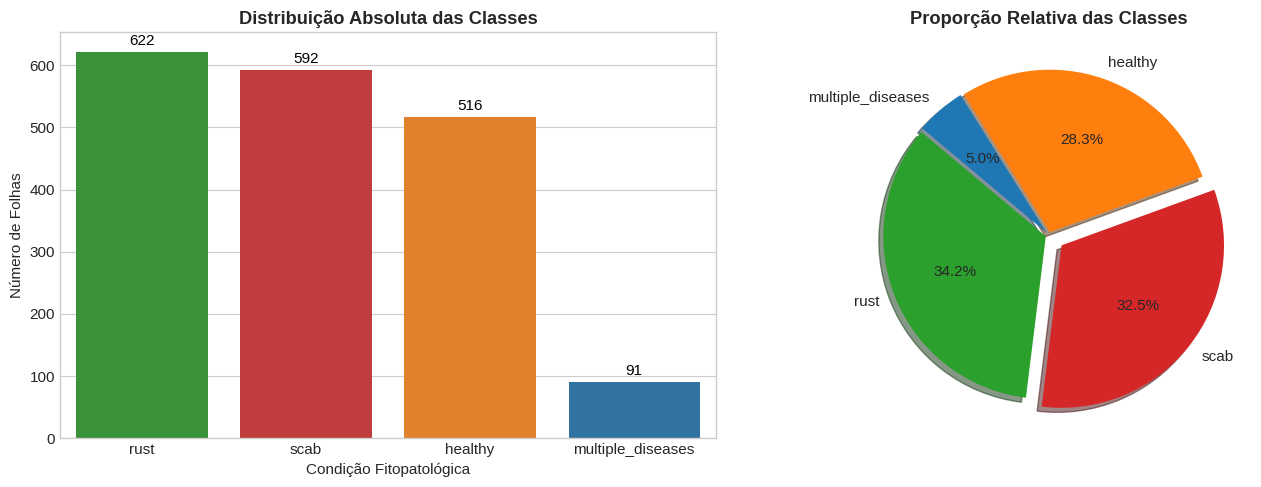

In [3]:
class_counts = train_df["label"].value_counts()
class_percentages = (class_counts / len(train_df)) * 100

summary_df = pd.DataFrame({
    "Quantidade": class_counts,
    "Proporção (%)": class_percentages.round(2)
})
display(summary_df)

# Gráfico comparativo: Barras e Pizza
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ["#2ca02c", "#d62728", "#ff7f0e", "#1f77b4"]

sns.barplot(x=class_counts.index, y=class_counts.values, ax=axes[0], palette=colors)
axes[0].set_title("Distribuição Absoluta das Classes", fontweight="bold")
axes[0].set_xlabel("Condição Fitopatológica")
axes[0].set_ylabel("Número de Folhas")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='baseline', fontsize=11, color='black', xytext=(0, 5),
                     textcoords='offset points')

axes[1].pie(class_counts.values, labels=class_counts.index, autopct='%1.1f%%', colors=colors, startangle=140,
            explode=[0.02, 0.1, 0.02, 0.02], shadow=True)
axes[1].set_title("Proporção Relativa das Classes", fontweight="bold")

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "eda_class_distribution.png"), dpi=300, bbox_inches="tight")
plt.show()

## 3. Visualização Amostral por Condição Fitopatológica
Carregamento e exibição de amostras representativas de folhas de macieira para cada uma das 4 categorias.

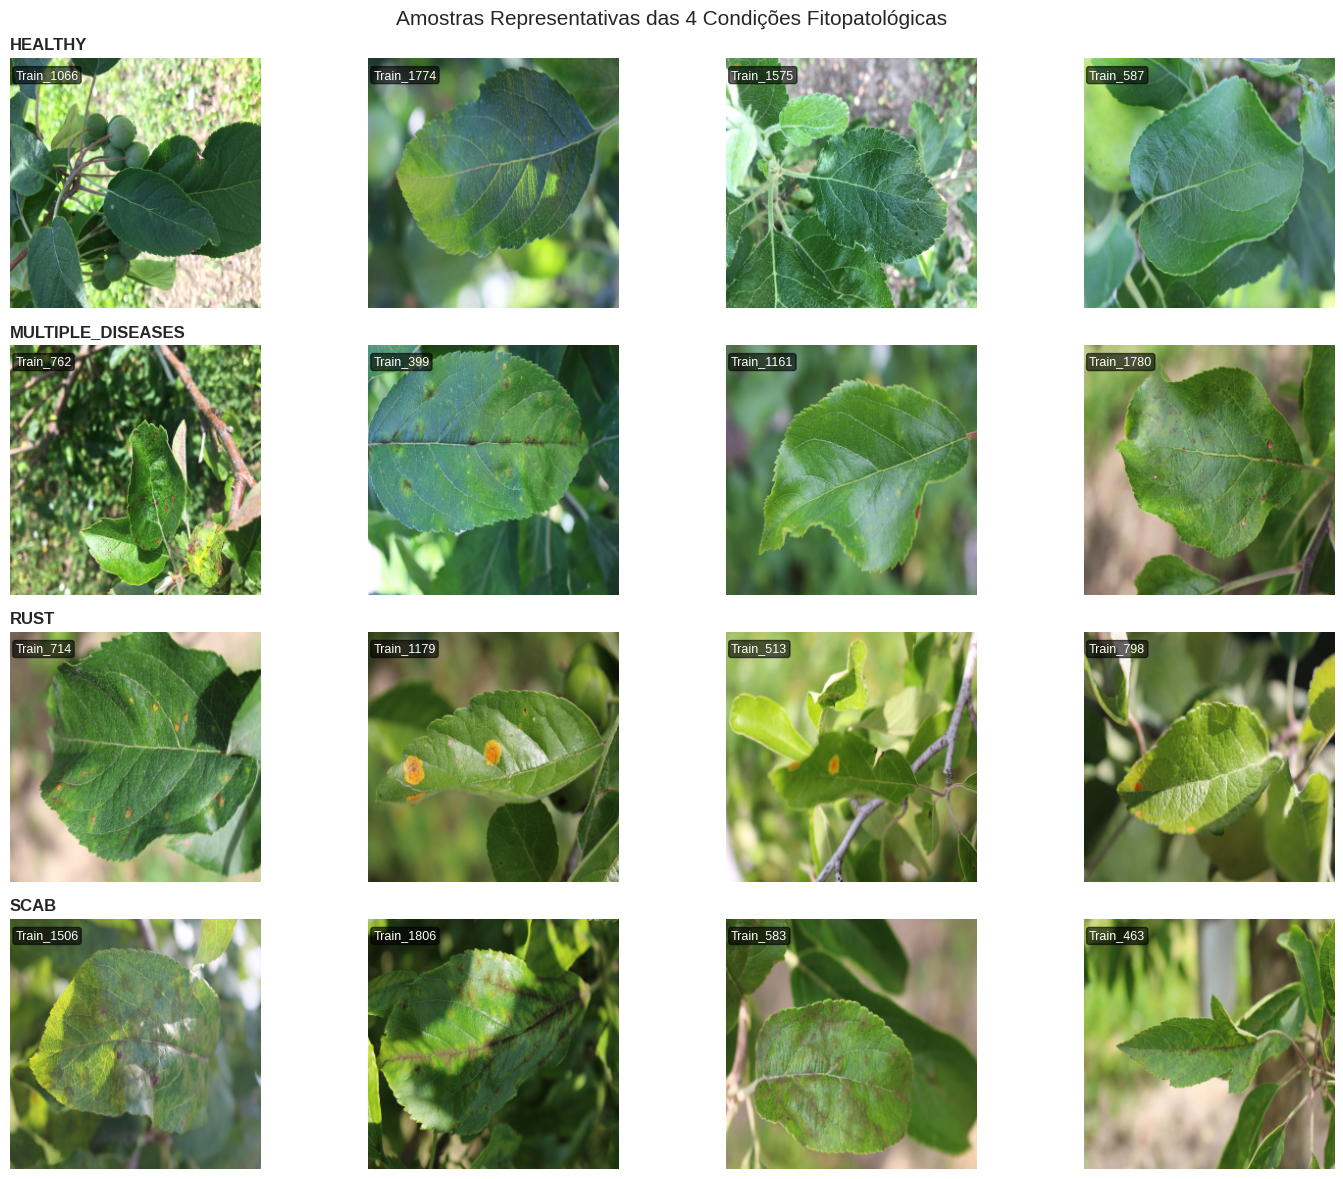

In [4]:
def load_image(image_id, target_size=(512, 512)):
    """Carrega imagem em RGB e redimensiona para tamanho fixo."""
    path = os.path.join(IMG_DIR, f"{image_id}.jpg")
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Imagem {path} não encontrada.")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    if target_size:
        img = cv2.resize(img, target_size, interpolation=cv2.INTER_AREA)
    return img

# Exibir um grid 4x4: 4 exemplos de cada classe
samples_per_class = 4
fig, axes = plt.subplots(len(TARGET_COLS), samples_per_class, figsize=(15, 12))

for row_idx, category in enumerate(TARGET_COLS):
    subset = train_df[train_df["label"] == category].sample(samples_per_class, random_state=42)
    for col_idx, (_, row) in enumerate(subset.iterrows()):
        ax = axes[row_idx, col_idx]
        img = load_image(row["image_id"], target_size=(256, 256))
        ax.imshow(img)
        ax.axis("off")
        if col_idx == 0:
            ax.set_title(f"{category.upper()}", fontsize=12, fontweight="bold", loc="left")
        ax.text(5, 20, f"{row['image_id']}", color="white", fontsize=9,
                bbox=dict(boxstyle="round,pad=0.2", fc="black", alpha=0.6))

plt.suptitle("Amostras Representativas das 4 Condições Fitopatológicas", fontsize=15, y=0.98)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "eda_sample_leaves_grid.png"), dpi=300, bbox_inches="tight")
plt.show()

## 4. Análise Estatística dos Canais de Cor (RGB & HSV)
Inspeção quantitativa da intensidade dos canais em amostras de cada classe para verificar assinaturas cromáticas das lesões (ex: elevação de tons amarelo-alaranjados na ferrugem).

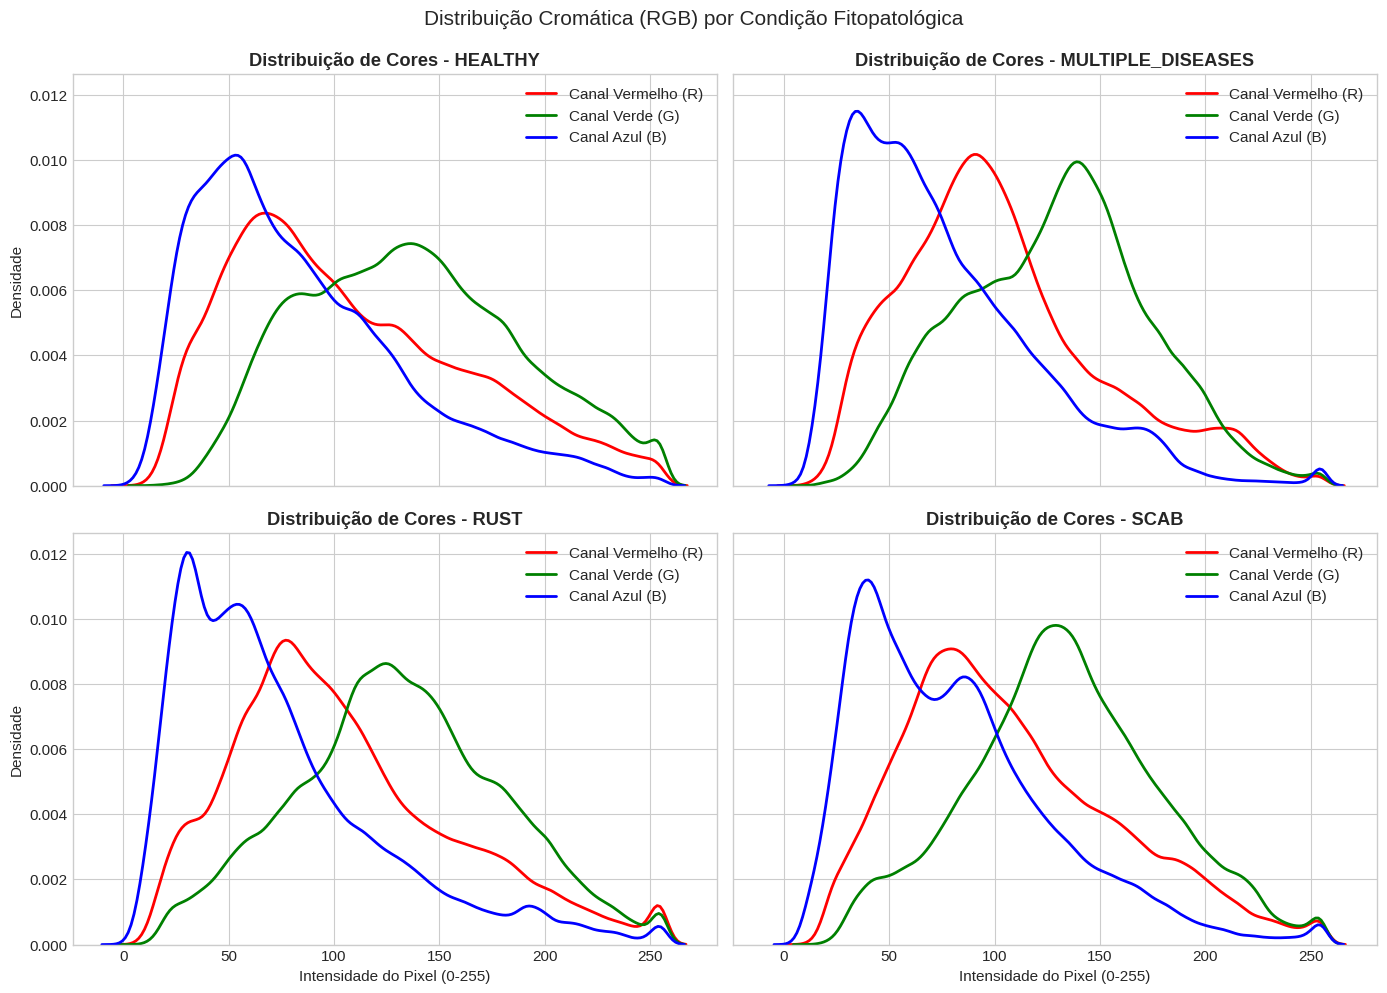

In [5]:
# Amostragem estratificada para cálculo de histograma médio por classe
N_SAMPLES = 25
channel_stats = []

for category in TARGET_COLS:
    sample_ids = train_df[train_df["label"] == category]["image_id"].sample(N_SAMPLES, random_state=42)
    r_vals, g_vals, b_vals = [], [], []
    for img_id in sample_ids:
        img = load_image(img_id, target_size=(128, 128))
        r_vals.append(img[:, :, 0].flatten())
        g_vals.append(img[:, :, 1].flatten())
        b_vals.append(img[:, :, 2].flatten())
    
    channel_stats.append({
        "class": category,
        "r": np.concatenate(r_vals),
        "g": np.concatenate(g_vals),
        "b": np.concatenate(b_vals)
    })

# Plotando a distribuição das intensidades médias
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
axes = axes.flatten()

for idx, item in enumerate(channel_stats):
    ax = axes[idx]
    sns.kdeplot(item["r"], ax=ax, color="red", label="Canal Vermelho (R)", lw=2)
    sns.kdeplot(item["g"], ax=ax, color="green", label="Canal Verde (G)", lw=2)
    sns.kdeplot(item["b"], ax=ax, color="blue", label="Canal Azul (B)", lw=2)
    ax.set_title(f"Distribuição de Cores - {item['class'].upper()}", fontweight="bold")
    ax.set_xlabel("Intensidade do Pixel (0-255)")
    ax.set_ylabel("Densidade")
    ax.legend(loc="upper right")

plt.suptitle("Distribuição Cromática (RGB) por Condição Fitopatológica", fontsize=15, y=0.99)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "eda_channel_distributions.png"), dpi=300, bbox_inches="tight")
plt.show()

## 5. Exploração de Visão Computacional Clássica (OpenCV)
Demonstração visual das técnicas avaliadas nos projetos de referência:
- **`cv2.GaussianBlur`**: Redução de ruídos de alta frequência.
- **`cv2.Canny`**: Detecção de bordas morfológicas (útil para inspecionar contornos de lesões na EDA).
- **Equalização de Histograma Global**: `cv2.equalizeHist` no canal de luminância.
- **CLAHE (*Contrast Limited Adaptive Histogram Equalization*)**: Realce adaptativo de contraste local no canal V (espaço HSV), preservando os 3 canais RGB para os modelos pré-treinados.

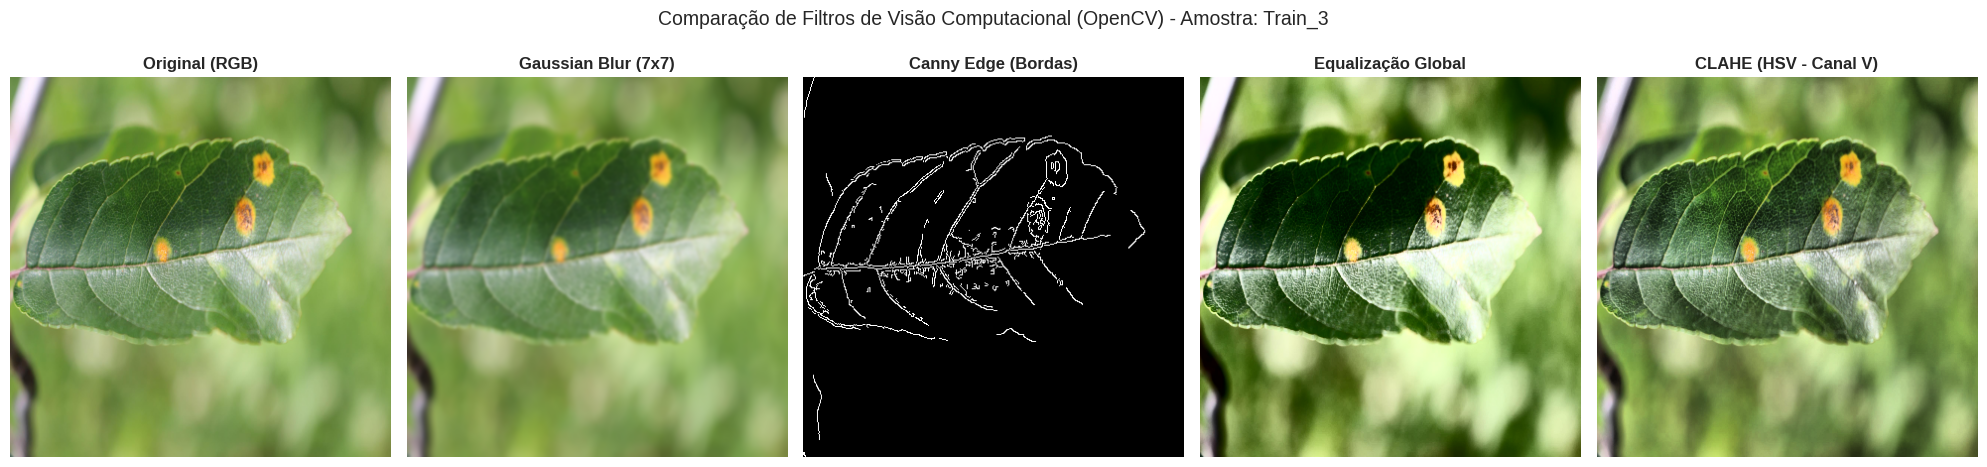

In [6]:
# Seleção de uma folha com lesões evidentes (rust)
sample_rust_id = train_df[train_df["label"] == "rust"].iloc[0]["image_id"]
img_orig = load_image(sample_rust_id, target_size=(384, 384))

# 1. Gaussian Blur (suavização)
img_blur = cv2.GaussianBlur(img_orig, (7, 7), 0)

# 2. Canny Edge Detection
img_gray = cv2.cvtColor(img_orig, cv2.COLOR_RGB2GRAY)
img_canny = cv2.Canny(img_gray, threshold1=100, threshold2=200)

# 3. Equalização Global de Histograma (no canal Y do YCrCb)
img_ycrcb = cv2.cvtColor(img_orig, cv2.COLOR_RGB2YCrCb)
img_ycrcb[:, :, 0] = cv2.equalizeHist(img_ycrcb[:, :, 0])
img_eqhist = cv2.cvtColor(img_ycrcb, cv2.COLOR_YCrCb2RGB)

# 4. CLAHE no espaço HSV (canal V)
img_hsv = cv2.cvtColor(img_orig, cv2.COLOR_RGB2HSV)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
img_hsv[:, :, 2] = clahe.apply(img_hsv[:, :, 2])
img_clahe = cv2.cvtColor(img_hsv, cv2.COLOR_HSV2RGB)

# Visualização comparativa lado a lado
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

transforms = [
    ("Original (RGB)", img_orig, None),
    ("Gaussian Blur (7x7)", img_blur, None),
    ("Canny Edge (Bordas)", img_canny, "gray"),
    ("Equalização Global", img_eqhist, None),
    ("CLAHE (HSV - Canal V)", img_clahe, None)
]

for idx, (title, img_plot, cmap) in enumerate(transforms):
    ax = axes[idx]
    if cmap:
        ax.imshow(img_plot, cmap=cmap)
    else:
        ax.imshow(img_plot)
    ax.set_title(title, fontweight="bold", fontsize=12)
    ax.axis("off")

plt.suptitle(f"Comparação de Filtros de Visão Computacional (OpenCV) - Amostra: {sample_rust_id}", fontsize=14, y=0.98)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "eda_opencv_filters_comparison.png"), dpi=300, bbox_inches="tight")
plt.show()

## 6. Demonstração de Data Augmentation
Visualização das operações de aumento de dados que serão injetadas dinamicamente no pipeline `tf.data` durante o treinamento para mitigar o sobreajuste e compensar a escassez de amostras.

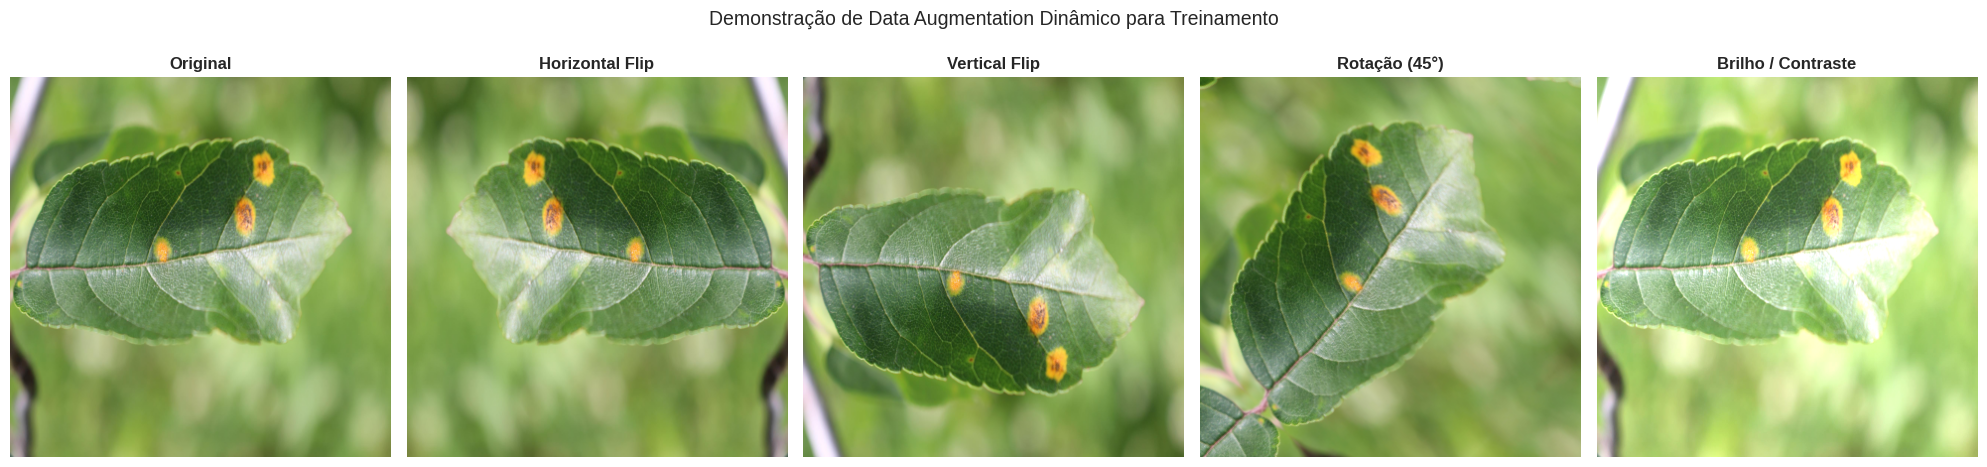

In [7]:
# Transformações com OpenCV para demonstração visual
h, w, _ = img_orig.shape

flip_h = cv2.flip(img_orig, 1) # Espelhamento horizontal
flip_v = cv2.flip(img_orig, 0) # Espelhamento vertical

# Rotação de 45 graus
M = cv2.getRotationMatrix2D((w // 2, h // 2), 45, 1.0)
rotated = cv2.warpAffine(img_orig, M, (w, h), borderMode=cv2.BORDER_REFLECT)

# Variação de brilho e contraste
bright = cv2.convertScaleAbs(img_orig, alpha=1.2, beta=20)

fig, axes = plt.subplots(1, 5, figsize=(20, 5))
aug_examples = [
    ("Original", img_orig),
    ("Horizontal Flip", flip_h),
    ("Vertical Flip", flip_v),
    ("Rotação (45°)", rotated),
    ("Brilho / Contraste", bright)
]

for idx, (title, img_plot) in enumerate(aug_examples):
    ax = axes[idx]
    ax.imshow(img_plot)
    ax.set_title(title, fontweight="bold", fontsize=12)
    ax.axis("off")

plt.suptitle("Demonstração de Data Augmentation Dinâmico para Treinamento", fontsize=14, y=0.98)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "eda_data_augmentation_examples.png"), dpi=300, bbox_inches="tight")
plt.show()

## 7. Conclusões e Diretrizes para as Próximas Etapas

Com base nos diagnósticos obtidos nesta Análise Exploratória:

1. **Estratégia de Validação:** Devido à disparidade entre classes (apenas 5% para `multiple_diseases` contra mais de 30% para `rust` e `scab`), toda divisão de treino/validação no `02_pipeline_single.ipynb` e no `03_grid_search_ensemble.ipynb` **deve ser estratificada** (`train_test_split(..., stratify=y)`).
2. **Ponderação de Classes:** O uso de **`class_weight`** no `model.fit()` será indispensável para penalizar erros na identificação de folhas com doenças múltiplas.
3. **Papel do CLAHE:** O realce no canal V do espaço HSV provou evidenciar manchas e lesões sem estourar as cores da folha, mantendo os 3 canais intactos para os backbones pré-treinados no ImageNet.
4. **Métricas Chave:** Além do **ROC-AUC** oficial e da Acurácia, o **Macro F1-Score** e a **Matriz de Confusão Normalizada** serão acompanhados para certificar que o modelo não possui pontos cegos nas classes raras.

---  
*Próximo passo: Executar o `02_pipeline_single.ipynb` para validar a Prova de Conceito (PoC) com `tf.data` e a arquitetura baseline.*